# Google tunable coupler: the qubit–coupler–qubit cell, a Quantcore-PDK rebuild, step by step

**What the chip is.** The two-qubit unit of Google's Sycamore processor: two frequency-tunable, Xmon-type grounded
transmons joined by a third, flux-tunable transmon (the *coupler*) through small capacitances. Tuning the coupler
moves the effective qubit–qubit coupling g̃ through zero (the *off* point, idle) to tens of MHz (gates): the scheme of
Yan et al., PR Applied 10, 054062 (2018), used in Sycamore (Arute et al., Nature 574, 505 (2019)). Each qubit has a
λ/4 readout on a common feedline, an XY drive line and a Z (flux) line; the coupler has its own Z line.

**This notebook rebuilds the cell in the Quantcore PDK; it is not a replica** (spec `docs/designs/google/google_tc_cell.md`).
No layout of Sycamore is public: the papers give the architecture and the targets, the layout is ours. Quantum Metal
`TransmonCrossFL` crosses (qubits and coupler, through `metal:`) carry **Quantcore trilayer SQUIDs** sized by the PDK
junction rule; Quantcore `BondPad`s, qcc routes, the PDK die frame (7.5 × 7.5 mm, QCT), sapphire 650 µm (εr 10.25)
and the qcc LOM do the rest.

| | from the source | adapted here (why) |
|---|---|---|
| architecture | Q–C–Q, grounded transmons, capacitive coupler (Arute SI §I: "a capacitor-coupled design"); λ/4 readout on a feedline, XY + Z lines (SI §III) | planar single die (Sycamore is two bump-bonded dies); one feedline without Sycamore's Purcell filter |
| qubit f_q | idle 6.661 GHz median, f_max 6.924 GHz (SI Table 2) | SQUID sweet spot at the idle frequency (6.67 GHz alone); the coupler pulls the qubits to ≈ 6.57 GHz at its off point |
| α | −208 MHz (SI Table 2) | −237 MHz alone, ≈ −193 MHz in the full cell: R_n ≥ 40 kΩ (PDK) caps E_J, so E_C is larger for the same f_q |
| readout | 4.618 GHz median, κ 0.64 MHz, g 72.3 MHz (SI Table 2) | 4.58 / 4.66 GHz (staggered around the median), κ ≈ 0.7 MHz; g ≈ 45 MHz (χ ≈ −0.2 MHz): the claw must stay shorter than the cross arm |
| coupling | g̃ from +5 to −40 MHz, "on" ≈ −20 MHz (SI §I); scheme and Eq. 5 from Yan et al. | qubit–coupler and direct capacitances set (Design 6) so the LOM off point falls inside the coupler range |
| junctions | Al/AlOx SQUIDs (not given) | Quantcore Nb/AlOx/Nb trilayer SQUIDs (PDK rule: Δ 1.4 meV, R_n 40–50 kΩ) |
| pads | (no layout) | **PDK pad rule**: every bond pad's etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | **PDK**: the content is shifted up to fill the die (it sat 738 µm low); Design 8 |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** The papers are cited for parameters only; the layout and code are ours (GPL, as the repository).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die, the seven bond pads, the feedline, the two qubit crosses with their trilayer SQUIDs,
their λ/4 hanger readouts, the coupler cross with the three declared coupling capacitances, the XY and Z control
lines, and then the whole chip (the centring, the targets and sim groups, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `google_tc_cell.v1.ipynb`; both save the same
`google_tc_cell.json`.

## Setup

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers of the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open every change below shows up live; with `QCC_LIVE=0` the
snapshots are rendered headless.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/google")
PDK = get_pdk()
EPS = est.substrate_eps(PDK)                     # sapphire, εr 10.25

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. The library applies every one of them: the frame and the cheese in the chip build,
the pad rule through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## The source targets

**The source targets** (Arute et al. 2019, SI Table 2 and §I). The two readouts are staggered around Sycamore's
median. Sycamore's readout g is turned into a dispersive-shift target (qcc's χ = E11 − E10 − E01 + E00
≈ 2g²α/(Δ(Δ + α))).

In [5]:
SRC = {"f_q_idle_GHz": 6.661, "f_q_max_GHz": 6.924, "alpha_MHz": -208.0, "f_r_GHz": 4.618, "kappa_MHz": 0.64,
       "g_qr_MHz": 72.3, "g_on_MHz": -20.0, "g_range_MHz": (5.0, -40.0)}
F_R = {"R1": 4.58, "R2": 4.66}                   # two readouts staggered around the Sycamore median (adapted)
D = SRC["f_q_idle_GHz"] - SRC["f_r_GHz"]
CHI_T = 2 * (SRC["g_qr_MHz"] / 1e3) ** 2 * (SRC["alpha_MHz"] / 1e3) / (D * (D + SRC["alpha_MHz"] / 1e3)) * 1e3
print(f"χ target from g = {SRC['g_qr_MHz']} MHz: {CHI_T:.3f} MHz")

χ target from g = 72.3 MHz: -0.580 MHz


# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedline is drawn as soon as its
pads exist (segment 3), each readout once its qubit is there (segment 5) and the control lines once their ends are
(segment 7). Every position is fixed by `X0`, `Y0`, `YF` and the cross geometry until the centring in segment 8, so the
order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the PDK's standard 7.5 mm die with its frame |
| 2 | seven bond pads: the feedline's two, the two XY pads, the three Z pads, on the PDK pad rule |
| 3 | the readout line: the straight feedline between its two pads |
| 4 | the two qubit crosses (`TransmonCrossFL`) with their trilayer SQUIDs and readout claws |
| 5 | the two λ/4 hanger readouts, claw → meander → 900 µm coupled section on the feedline |
| 6 | the coupling: the coupler cross TC between the qubits and the three declared capacitances |
| 7 | the control routing: the two XY ends with their lines, the three Z (flux) lines |
| 8 | the whole chip: the centring, the targets and sim groups, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip on the PDK's standard 7.5 mm die. The build draws the frame round it:
L dicing markers (1000/0), 3 × 3 alignment grids (1001/0) in the corners, the chip boundary (100/0) and the device ID
`GTC2Q` on a free edge.

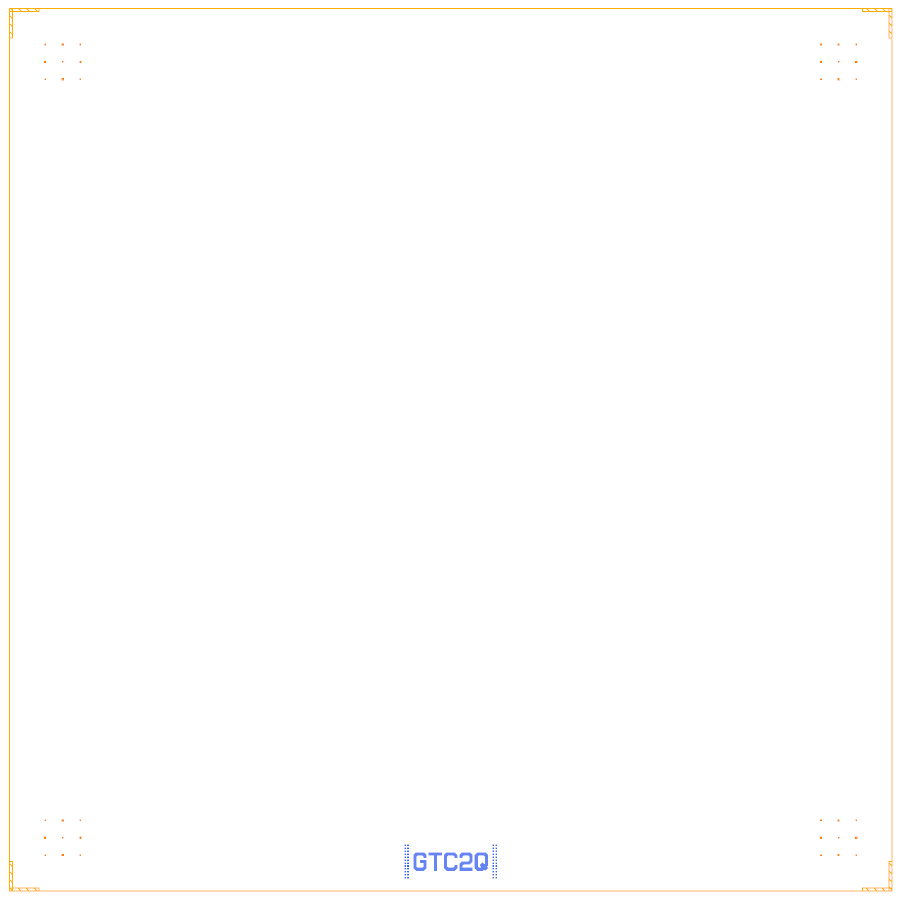

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/google/google_tc_cell_die.png')

In [6]:
W = H = 7500                                     # PDK standard die
d = Designer("google_tc_cell", box=(0, 0, W, H), chip={"name_chip": "GTC2Q"}, live=LIVE)
layout_step(d, OUT / "google_tc_cell_die.png", size=(900, 900), width=320)

## Design 2 · Bond pads: the PDK pad rule

Seven Quantcore `BondPad`s: the feedline's two (west and east edges, at the feedline height `YF`), the two XY drive
pads (west and east, at the qubit row `Y0`) and the three Z pads on the south edge. The PDK puts the outer edge of
every pad's etch **`frame.pad_edge` = 100 µm from the die edge**: `edge="auto"` slides each pad perpendicular to
its nearest edge until that holds, keeping its position along the edge. `pads_md(d)` lists the distances.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FL_in | `BondPad` | w | 100.0 | ✓ |
| FL_out | `BondPad` | e | 100.0 | ✓ |
| XY1 | `BondPad` | w | 100.0 | ✓ |
| XY2 | `BondPad` | e | 100.0 | ✓ |
| Z1 | `BondPad` | s | 100.0 | ✓ |
| ZC | `BondPad` | s | 100.0 | ✓ |
| Z2 | `BondPad` | s | 100.0 | ✓ |

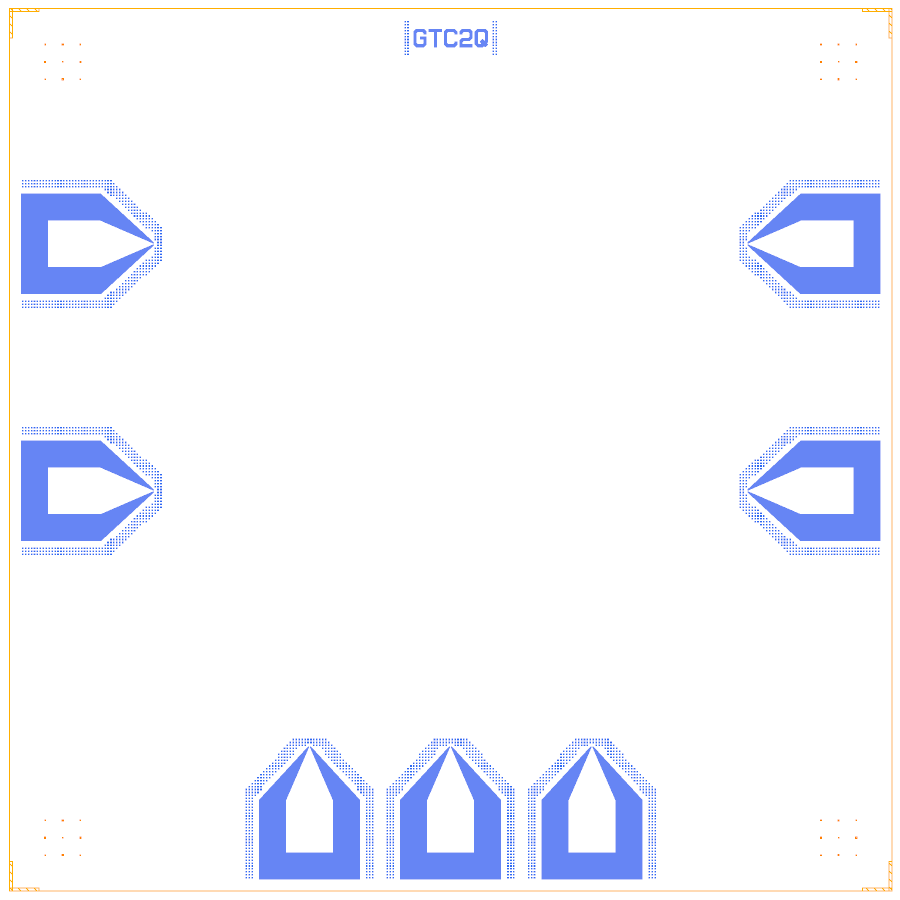

**On the chip so far:** 7 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 7 component(s) `FL_in`, `FL_out`, `XY1`, `XY2`, `Z1`, `ZC`, `Z2`.

WindowsPath('examples/designs/google/google_tc_cell_pads.png')

In [7]:
X0, Y0, YF = 3750, 3400, 5500                    # coupler centre, qubit row, feedline (before the centring of Design 8)
pad = lambda n, x, y, r: d.add(n, "BondPad", at=(x, y), rot=r, edge="auto")
P = {"FL_in": pad("FL_in", 1150, YF, -90), "FL_out": pad("FL_out", W - 1150, YF, 90),
     "XY1": pad("XY1", 1150, Y0, -90), "XY2": pad("XY2", W - 1150, Y0, 90),
     "Z1": pad("Z1", 2550, 1150, 0), "ZC": pad("ZC", X0, 1150, 0), "Z2": pad("Z2", W - 2550, 1150, 0)}
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "google_tc_cell_pads.png", size=(900, 900), width=320)

## Design 3 · Readout: the feedline

- **Feedline:** a straight 10/6 µm CPW between the two feedline pads. It needs no qubit, so it comes first; both
readouts will hang on it (Design 5).

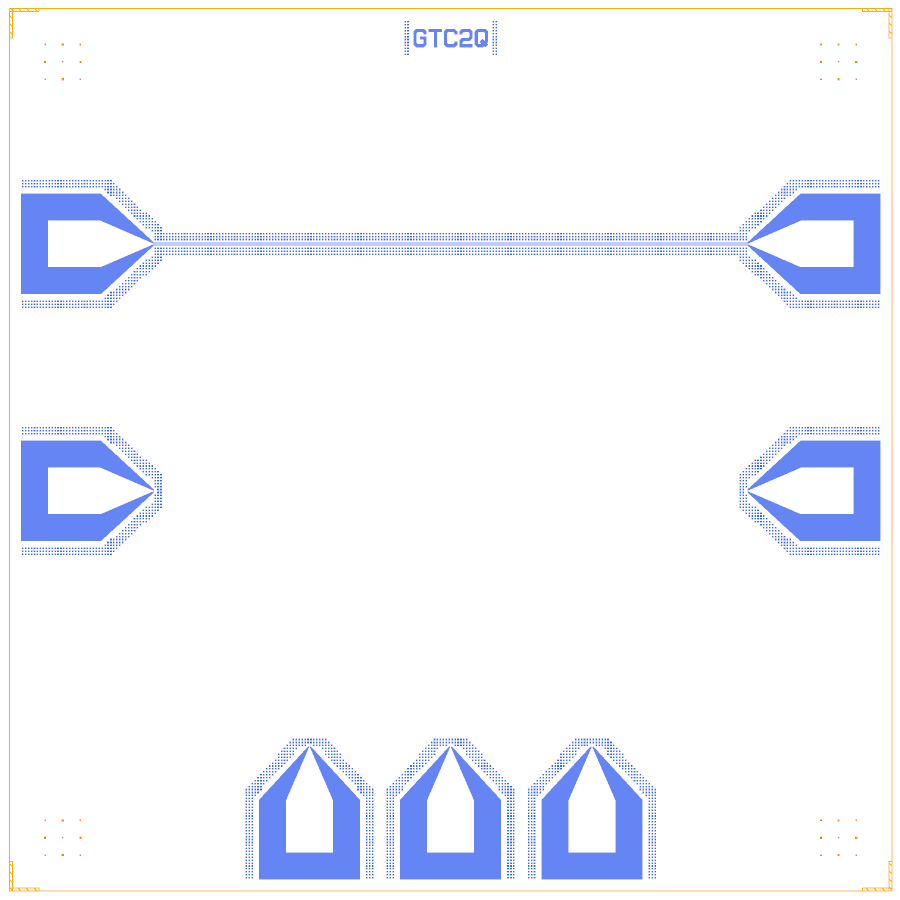

**On the chip so far:** 7 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/designs/google/google_tc_cell_s3_feedline.png')

In [8]:
fl = d.route("FL", P["FL_in"].a, P["FL_out"].a)                      # straight feedline, 10/6 µm
layout_step(d, OUT / "google_tc_cell_s3_feedline.png", size=(900, 900), width=320)

## Design 4 · Qubit placement: two Xmon crosses with trilayer SQUIDs

**The junctions.** Qubits and coupler each carry a Quantcore trilayer SQUID drawn for L_J = 6.1 nH at zero flux,
the low end of the PDK window (R_n ≈ 40 kΩ: the largest E_J, so the highest f_q per E_C). `trilayer_junction(...,
squid=True)` returns the cell parameters that draw it and the values the LOM uses.

The DRC's `pdk_rn` judges the device, the SQUID's two junctions in parallel: ≈ 40 kΩ (each junction ≈ 80 kΩ),
inside the window, so these SQUIDs raise no warning.

In [9]:
QJ_PARAMS, QJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)
CJ_PARAMS, CJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)
print("qubit / coupler SQUID (drawn, zero flux):", QJ, "→ parallel R_n",
      round(rn_from_lj(QJ["Lj_nH"]) / 1e3, 1), "kΩ; each junction", round(2 * rn_from_lj(QJ["Lj_nH"]) / 1e3, 1), "kΩ")

qubit / coupler SQUID (drawn, zero flux): {'Lj_nH': 6.0129, 'Cj_fF': 16.8} → parallel R_n 40.2 kΩ; each junction 80.4 kΩ


**The geometry** (µm). Qubit crosses 160 µm arms; a smaller coupler cross (70 µm arms) puts the coupler's maximum
frequency above the qubits. Arm tips face each other across a 100 µm gap. The readout claw wraps the qubit's north
arm tip; its fingers stop short of the east and west arms (`claw_length` < arm length, else the DRC's `pdk_claw`).

<metal:TransmonCrossFL Q1 ports=['flux_line', 'readout', 'squid_a', 'squid_b']>


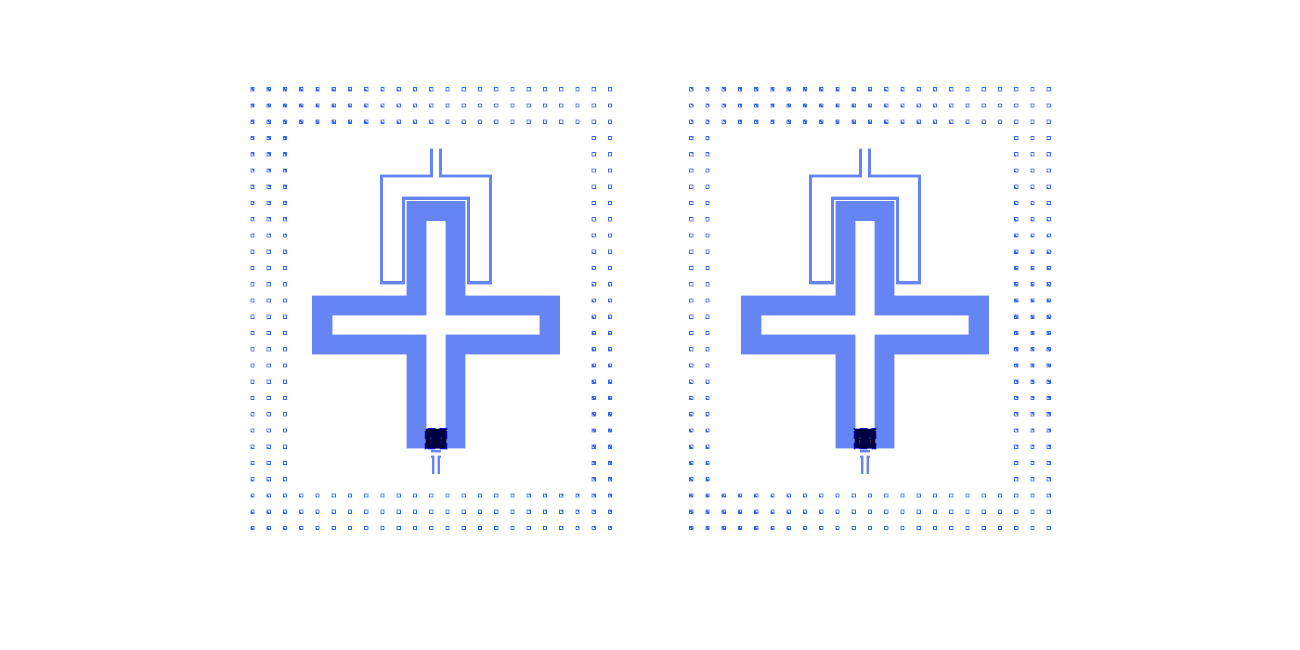

**On the chip so far:** 7 pads · 2 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 2 component(s) `Q1`, `Q2`.

WindowsPath('examples/designs/google/google_tc_cell_s4_qubits.png')

In [10]:
LQ, WQ, GQ = 160, 30, 30                         # qubit cross: arm length from the centre, arm width, gap
LC, WC, GC = 70, 20, 20                          # coupler cross (smaller: f_c,max above the qubits)
GAP = 100                                        # qubit arm tip ↔ coupler arm tip
S = LQ + GAP + LC                                # qubit ↔ coupler centre pitch
L_READ = {"R1": 6215, "R2": 6095}                # λ/4 lengths (claw → shorted hanger end), set for F_R with the LOM
K_LEN = 900                                      # hanger coupling length (κ ≈ 0.64 MHz)
CLAW = dict(connector_type="0", claw_length=130, ground_spacing=3, claw_width=30, claw_gap=4, connector_location="90")

cross = lambda name, x, L, w, g, pads, jp, j: d.add(name, "metal:TransmonCrossFL", at=(x, Y0), junction=j,
                                                   cross_length=L, cross_width=w, cross_gap=g,
                                                   connection_pads=pads, **jp)
q1 = cross("Q1", X0 - S, LQ, WQ, GQ, {"readout": CLAW}, QJ_PARAMS, QJ)
q2 = cross("Q2", X0 + S, LQ, WQ, GQ, {"readout": CLAW}, QJ_PARAMS, QJ)
print(q1)
layout_step(d, OUT / "google_tc_cell_s4_qubits.png", box=(X0 - S - 600, Y0 - 500, X0 + S + 600, Y0 + 500),
            size=(1300, 650), width=560)

## Design 5 · Readout: two λ/4 hangers on the feedline

- **Readouts:** each λ/4 runs from the qubit's claw (open end) up and across to a **hanger** on the feedline: a
  900 µm coupled section beside the line, shorted at its end. `fl.hanger(near=(x, y), length=...)` gives that end spec: it centres the coupler at
  the feedline point nearest (x, y), so it stays put when the pads (and so the feedline's start) move;
  `meander=` sets the total length (from the LOM calibration for 4.58 / 4.66 GHz) and the router adds the meander on
  the vertical run. That meander is one KQC
`Meander` for the length the waypoint path leaves over.

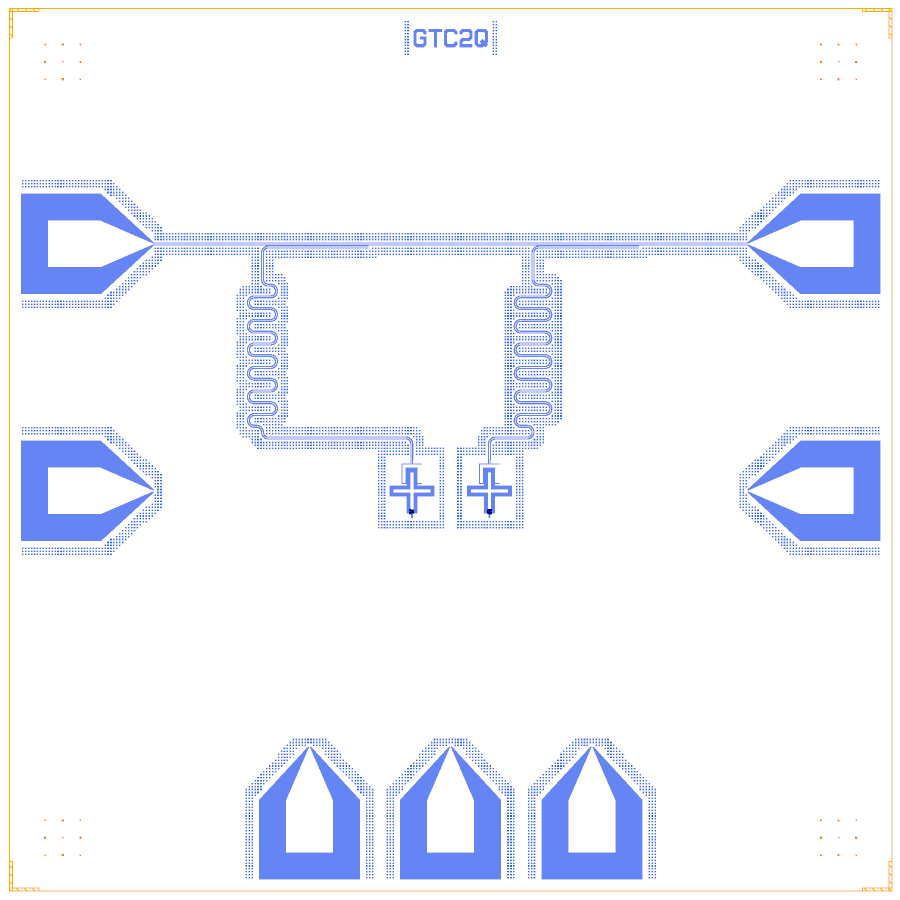

**On the chip so far:** 7 pads · 2 qubits · 0 other components · 3 routes · 0 declared couplings. **This step added** 2 route(s) `R1`, `R2`.

WindowsPath('examples/designs/google/google_tc_cell_s5_readouts.png')

In [11]:
for k, q, sgn in ((1, q1, -1), (2, q2, 1)):
    xc = X0 + sgn * 1150                                             # hanger centre
    xv = xc - K_LEN / 2                                              # the readout rises to the hanger start
    d.route(f"R{k}", q.readout, fl.hanger(near=(xc, YF), length=K_LEN, side="right", ground_gap=4, end="short"),
            meander=L_READ[f"R{k}"], r=50, nodes=[(X0 + sgn * S, Y0 + 450), (xv, Y0 + 450), (xv, YF - 300)])
layout_step(d, OUT / "google_tc_cell_s5_readouts.png", size=(900, 900), width=320)

## Design 6 · Coupling: the coupler cross and the declared capacitances

**The coupler** `TC`: a smaller cross (70 µm arms, its own trilayer SQUID drawn as the qubits', Design 4) centred
between the qubits, its arm tips facing theirs across the 100 µm gap (`S`), so its maximum frequency sits above the
qubits. Tuning its SQUID moves the qubit–qubit coupling through zero (LOM 1 b).

**The couplings no route carries.** The arm-tip capacitances (qubit ↔ coupler, end-on across 100 µm) and the direct
qubit ↔ qubit capacitance across the coupler (screened by it: the knob that sets the off point, Yan Eq. 4–5) are
rough coplanar-strip estimates, declared with `d.couple`. The Q3D job `core` (Simulate 2) replaces them.

C(Q ↔ C) ≈ 2.35 fF, C(Q1 ↔ Q2) ≈ 0.282 fF
<metal:TransmonCrossFL TC ports=['flux_line', 'squid_a', 'squid_b']>


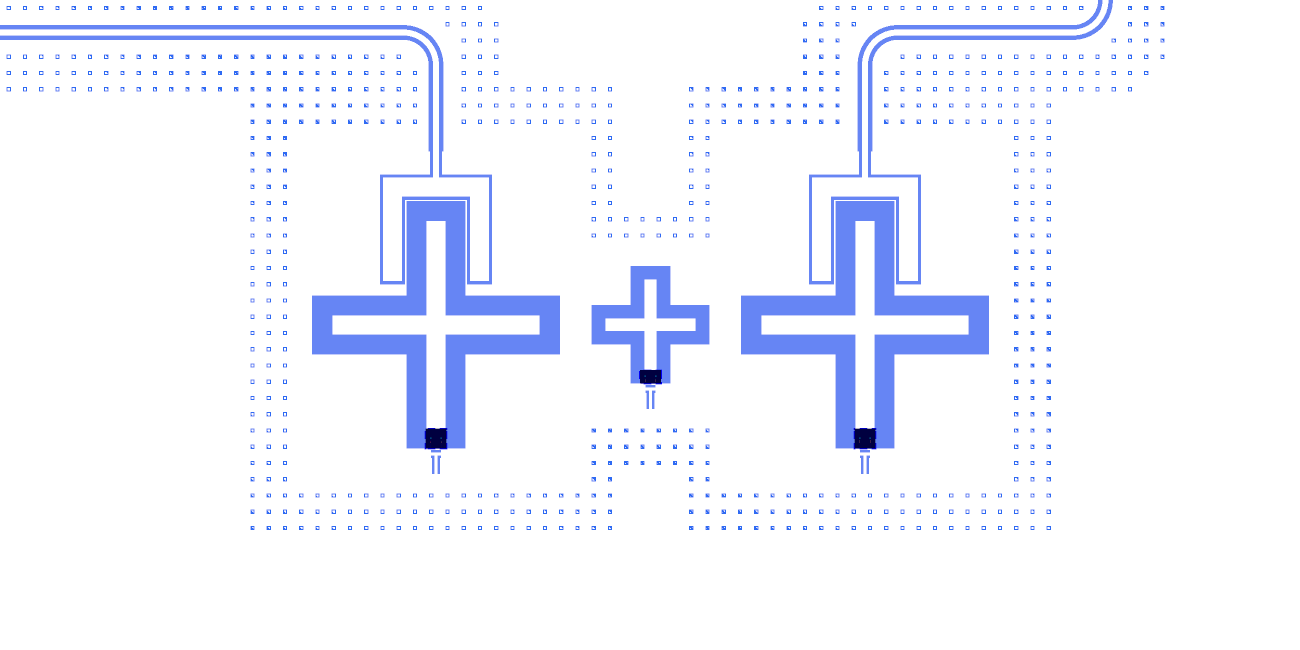

**On the chip so far:** 7 pads · 3 qubits · 0 other components · 3 routes · 3 declared couplings. **This step added** 1 component(s) `TC`.

WindowsPath('examples/designs/google/google_tc_cell_components.png')

In [12]:
tc = cross("TC", X0, LC, WC, GC, {}, CJ_PARAMS, CJ)                 # the coupler: a small Xmon with a SQUID
C_QC = round(est.coplanar_coupling(WQ, LQ, LC, GAP, EPS), 2)      # qubit arm tip ↔ coupler arm tip, end-on
C_QQ = round(est.coplanar_coupling(WQ, LQ, LQ, 2 * GAP + 2 * LC, EPS, screening=0.15), 3)
print(f"C(Q ↔ C) ≈ {C_QC} fF, C(Q1 ↔ Q2) ≈ {C_QQ} fF")
d.couple("Cg_Q1_TC", "Q1", "TC", C_fF=C_QC, note="Q1 east arm tip ↔ coupler west arm tip, 100 µm (CPS estimate)")
d.couple("Cg_TC_Q2", "TC", "Q2", C_fF=C_QC, note="coupler east arm tip ↔ Q2 west arm tip, 100 µm (CPS estimate)")
d.couple("Cg_Q1_Q2", "Q1", "Q2", C_fF=C_QQ, note="Q1 ↔ Q2 across the coupler (CPS, screening 0.15)")
print(tc)
layout_step(d, OUT / "google_tc_cell_components.png", box=(X0 - S - 600, Y0 - 500, X0 + S + 600, Y0 + 500),
            size=(1300, 650), width=560)

## Design 7 · Routing: the XY and Z lines

**XY ends:** open CPW ends facing the qubits' outer arm tips (20 µm of ground between), the drive lines' targets.

- **XY lines:** straight from the XY pads to the open ends beside the qubits.
- **Z lines:** each cross's flux T-line (`flux_line`) to its south pad, with waypoints.

{'FL': 5050.0, 'R1': 6215.0, 'R2': 6095.0, 'XY1_line': 1979.0, 'XY2_line': 1979.0, 'Z1_line': 2773.6, 'ZC_line': 2046.5, 'Z2_line': 2773.6}


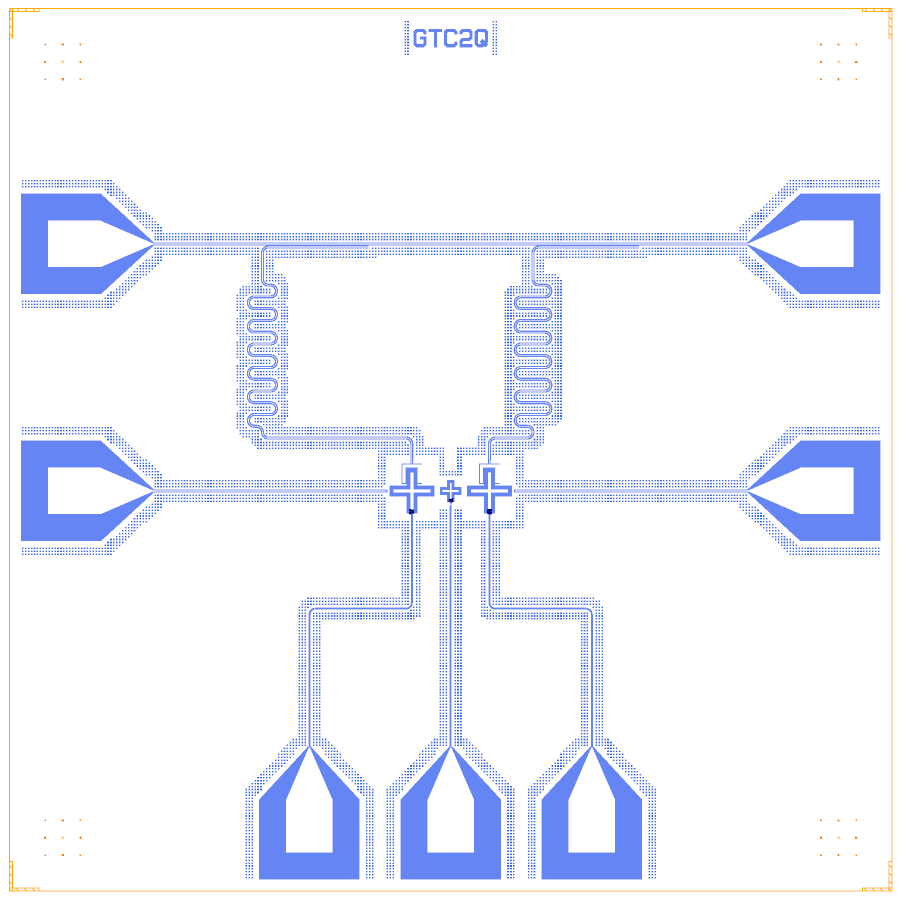

**On the chip so far:** 7 pads · 3 qubits · 2 other components · 8 routes · 3 declared couplings. **This step added** 2 component(s) `XY1_end`, `XY2_end` and 5 route(s) `XY1_line`, `XY2_line`, `Z1_line`, `ZC_line`, `Z2_line`.

WindowsPath('examples/designs/google/google_tc_cell_s7_control.png')

In [13]:
# XY drive ends: open CPW ends facing the qubits' outer arm tips (20 µm of ground between)
xy1 = d.add("XY1_end", "metal:OpenToGround", at=(X0 - S - LQ - GQ - 26, Y0), rot=0)
xy2 = d.add("XY2_end", "metal:OpenToGround", at=(X0 + S + LQ + GQ + 26, Y0), rot=180)
d.route("XY1_line", P["XY1"].a, xy1.open)
d.route("XY2_line", P["XY2"].a, xy2.open)
d.route("Z1_line", q1.flux_line, P["Z1"].a, r=50, nodes=[(X0 - S, 2400), (2550, 2400)])
d.route("ZC_line", tc.flux_line, P["ZC"].a, r=50)
d.route("Z2_line", q2.flux_line, P["Z2"].a, r=50, nodes=[(X0 + S, 2400), (W - 2550, 2400)])
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "google_tc_cell_s7_control.png", size=(900, 900), width=320)

## Design 8 · The whole chip: centring, targets, sim groups, save

**Centring.** The PDK wants the content in the middle of the die. Laid out as above it sits 738 µm low: the feedline is only
2.1 mm above the qubit row, so the upper third of the die is empty. `center_in_die(d)` measures the bounding box of
every instance and route and shifts them all (positions, waypoints) to centre it. The three Z pads keep `edge="auto"`,
so they stay 100 µm from the south edge and their lines get longer; the feedline and XY pads slide up along the side
edges.

The box of everything is then ≈ 0.4 mm low, not zero: the Z pads cannot leave the south edge, and a second shift
would put the feedline pads into the corner marker areas. The qubits now sit 0.39 mm above the die centre with the
feedline above them, and the die is filled evenly. From the v1 run: shift (0, +737.5) µm, qubit row Y0 = 4137.5,
feedline YF = 6237.5; `pdk_report` then gives the content centre (0, −369) µm.

**Targets and FEM groups.** The targets are the source's (qubit idle frequency and α, the staggered readouts with
Sycamore's κ). Two sim groups define the FEM boxes: the Q–C–Q `core` with the XY ends (C-matrix: replaces the three
estimates and gives the XY drive capacitances) and `Q1_read`, Q1 with its readout.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the feedline and the readouts were added before the coupler, its couplings and the XY ends here), so `git diff` stays empty.

shift applied (µm):

 (0.0, 737.5) → qubit row Y0 = 4137.5 , feedline YF = 6237.5


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FL_in | `BondPad` | w | 100.0 | ✓ |
| FL_out | `BondPad` | e | 100.0 | ✓ |
| XY1 | `BondPad` | w | 100.0 | ✓ |
| XY2 | `BondPad` | e | 100.0 | ✓ |
| Z1 | `BondPad` | s | 100.0 | ✓ |
| ZC | `BondPad` | s | 100.0 | ✓ |
| Z2 | `BondPad` | s | 100.0 | ✓ |

**Same design as before:** `examples/designs/google/google_tc_cell.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer google_tc_cell: 12 instances, 8 routes, live=False> → examples\designs\google\google_tc_cell.json


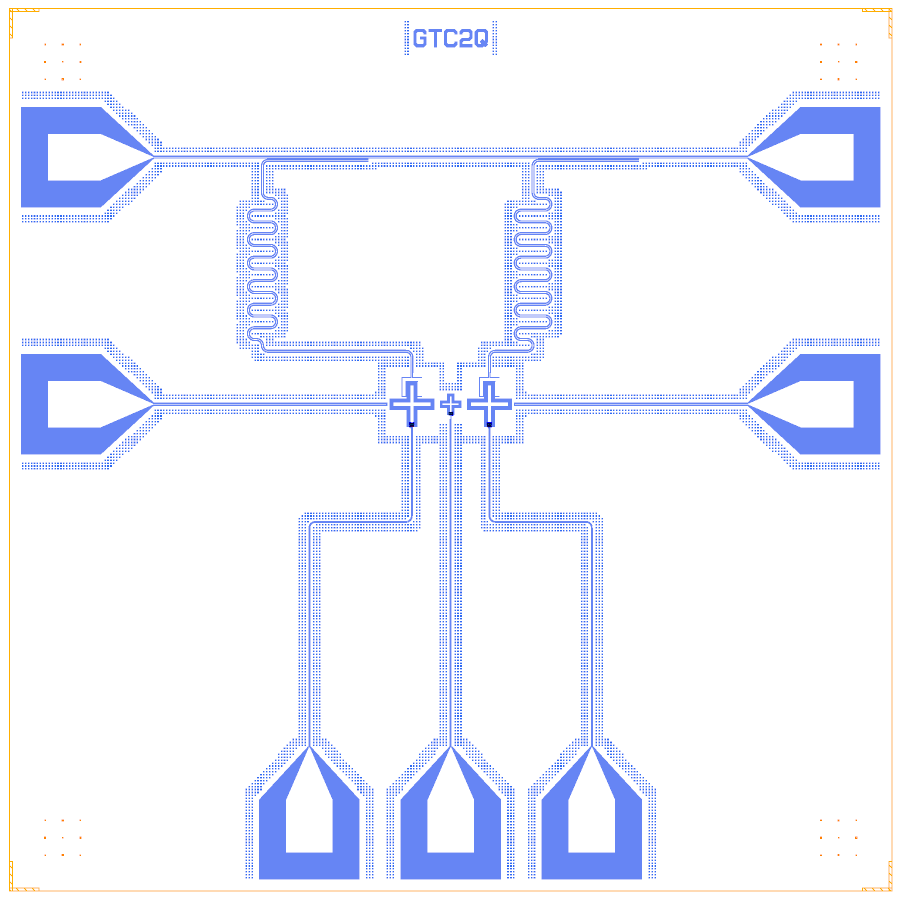

**On the chip so far:** 7 pads · 3 qubits · 2 other components · 8 routes · 3 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/google/google_tc_cell_s8_chip.png')

In [14]:
DX, DY = center_in_die(d)
X0, Y0, YF = X0 + DX, Y0 + DY, YF + DY           # the cell's reference points after the shift
print("shift applied (µm):", (DX, DY), "→ qubit row Y0 =", Y0, ", feedline YF =", YF)
rebuild(d)
display(Markdown(pads_md(d)))
d.targets(Q1={"f_q_GHz": SRC["f_q_idle_GHz"], "alpha_MHz": SRC["alpha_MHz"]},
          Q2={"f_q_GHz": SRC["f_q_idle_GHz"], "alpha_MHz": SRC["alpha_MHz"]},
          R1={"f_GHz": F_R["R1"], "kappa_MHz": SRC["kappa_MHz"]}, R2={"f_GHz": F_R["R2"], "kappa_MHz": SRC["kappa_MHz"]})
d.sim_group("core", ["Q1", "TC", "Q2", "XY1_end", "XY2_end"], margin_um=60, analyses=["q3d_cmatrix"])
d.sim_group("Q1_read", ["Q1", "R1"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN, same = save_design(d, OUT / "google_tc_cell.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "google_tc_cell_s8_chip.png", size=(900, 900), width=320)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity and the PDK margins. Three kinds of finding:
- **errors** (shorts, routes through components, opens): none expected;
- **warnings**: the junction attachment points `squid_a` / `squid_b` of the three crosses (the cell draws the
  trilayer SQUID across the gap itself), not route ends;
- **PDK design warnings**: none expected (the SQUIDs' parallel R_n ≈ 40 kΩ is in the window, Design 4; the f_q
  targets are in 4–8 GHz; every pad at 100 µm).

From the v1 run: **0 errors · 6 warnings (`dangling_port`) · 0 PDK design warnings**; the drawn SQUID is 6.01 nH, parallel
R_n 40.2 kΩ (each junction 80.4 kΩ).

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` maps every component's ports to circuit nodes:
- `TransmonCrossFL` → a grounded island with its SQUID (the drawn trilayer L_J / C_J), a node for the readout claw,
  the flux line as a control;
- each claw → hanger route → a λ/4 `TLres` with a hanger κ into the feedline `FL` (one conductor between the two
  50 Ω pads);
- the XY ends → 50 Ω drive ports ending open;
- the three `d.couple` capacitances → Q1–TC, TC–Q2 and Q1–Q2;
- the Z-line pads drop out: the flux T-line shorts to ground.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed values; targets in brackets). The feedline is a 25 Ω load outside the
selection; the coupler is not in these groups, so the qubits sit ≈ 0.1 GHz above their value in the full cell (c).
The λ/4 lengths were calibrated before the Nb film's kinetic inductance (PDK `kinetic`) entered the LOM;
with it every line is ≈ 1.6 % slower, so f_r lands ≈ 75 MHz below its target. Flagged, not retuned (values are not
the point of the rebuild). From the v1 run: f_q 6.6675 GHz, α −236.5 MHz; R1 4.5054 / R2 4.5846 GHz; κ 0.671 /
0.705 MHz; χ −0.177 / −0.202 MHz.

In [ ]:
read = {"Q1+R1": ["Q1", "R1", "FL"], "Q2+R2": ["Q2", "R2", "FL"]}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))
display(Markdown(f"Dispersive-shift target from Sycamore's g = {SRC['g_qr_MHz']} MHz: χ ≈ {CHI_T:.2f} MHz"))

**(b) Coupler sweep: g̃ and ZZ against the coupler frequency.** The coupler's SQUID L_J is stepped from its drawn
zero-flux value (6.0 nH, f_c,max) upwards — L_J(Φ) = L_J0/|cos πΦ|, so each row is a flux bias Φ. With the two
(identical) qubits degenerate, the dressed splitting of their levels is 2|g̃|; the sign is that of Yan's Eq. 5
evaluated on the same LOM capacitances (listed too: Eq. 5 is perturbative, the LOM splitting is the full circuit,
and they part where the coupler comes within a few hundred MHz of the qubits). For ZZ, Q2 is detuned by its L_J
(`DETUNE_LJ`) and the static ZZ of the detuned pair is read from the dressed levels.

From the v1 run: g̃ goes from +5.0 MHz at f_c,max (8.765 GHz) through 0 at f_c ≈ 7.772 GHz (L_J,c 7.56 nH, Φ ≈ 0.208 Φ0)
to −35.7 MHz at 6.868 GHz; Yan's Eq. 5 follows the LOM splitting within ≈ 0.4 MHz down to |g̃| ≈ 3 MHz and parts
from it below f_c ≈ 7.3 GHz. The detuned pair's ZZ is −89 kHz near the off point and −10 MHz at the bottom.

In [ ]:
LJ_C = [6.0, 6.25, 6.5, 6.75, 7.0, 7.25, 7.5, 7.75, 8.0, 8.5, 9.0, 9.25, 9.5, 9.75]
DETUNE_LJ = 6.9                                  # Q2's L_J for the ZZ column (≈ 0.4 GHz below Q1)
sweep = coupler_sweep(d, ["Q1", "TC", "Q2"], "Q1", "Q2", "TC", LJ_C, detune_lj=DETUNE_LJ)
display(Markdown(coupler_sweep_md(sweep)))
display(Markdown(f"ZZ column: Q2 at {sweep[0]['f_q2_detuned_GHz']:.3f} GHz (L_J {DETUNE_LJ} nH), "
                 f"Q1 at {sweep[0]['f_q1_GHz']:.3f} GHz."))
off = off_point(sweep)
display(Markdown(f"**Off point:** g̃ = 0 at f_c ≈ {off['f_c_GHz']:.3f} GHz (L_J,c ≈ {off['lj_nH']:.2f} nH, "
                 f"Φ ≈ {off['flux_phi0']:.3f} Φ0)" if off else "**Off point:** not inside the sweep"))
plot_coupler_sweep(sweep, OUT / "google_tc_cell_sweep.png", title="Quantcore rebuild of the Sycamore Q–C–Q cell (LOM)")

**(c) The whole cell at the off point and at the "on" point** (Q1, R1, TC, Q2, R2 and the feedline together, Q2
detuned as in the ZZ column): QuTiP dressed values, so the qubit frequencies include the coupler's pull, and the
static ZZ at the idle (off) and gate (on) biases. The junction values are changed in the LOM only (the drawing and
the saved design keep the design values).

From the v1 run: at the off point (7.56 nH) Q1 sits at 6.566 GHz and the detuned Q2 at 6.118 GHz, α ≈ −193 MHz, the static
ZZ(Q1–Q2) −82 kHz; at the "on" bias (9.25 nH, g̃ ≈ −18.8 MHz) ZZ(Q1–Q2) is −1.83 MHz.

In [ ]:
on = min(sweep, key=lambda r: abs(r["g_MHz"] - SRC["g_on_MHz"]))
cell = {}
d["Q2"].spec["junction"] = {**QJ, "Lj_nH": DETUNE_LJ}            # detuned pair (LOM only, the drawing is unchanged)
for label, lj in (("off", off["lj_nH"] if off else LJ_C[0]), ("on", on["lj_nH"])):
    d["TC"].spec["junction"] = {**CJ, "Lj_nH": round(lj, 4)}    # the coupler at this bias (LOM only)
    cell.update(simulate_groups(d, {f"cell, coupler {label} ({lj:.2f} nH)": ["Q1", "R1", "TC", "Q2", "R2", "FL"]},
                                max_modes=5))
d["Q2"].spec["junction"], d["TC"].spec["junction"] = dict(QJ), dict(CJ)   # back to the design values
display(Markdown(groups_md(cell)))
display(Markdown(zz_md(cell)))

## LOM 2 · The LOM in two plots

The coupler sweep has its plot in LOM 1 (b). Here the pair and whole-cell results as pictures: (a) every normal mode
of each simulated group (QuCat; circles are the qubits and the coupler, squares the readouts; filled markers are the
QuTiP dressed values; red bars the targets), (b) the dispersive shift |χ| of each readout. From the v1 run the
readouts sit ≈ 75 MHz below their red bars (the Nb kinetic inductance, LOM 1 a) and the qubits, alone, on theirs.

In [ ]:
plot_lom({**results, **cell}, OUT / "google_tc_cell_lom.png", targets=d.data["targets"],
         title="google_tc_cell: LOM, pairs and the whole cell")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The readout's χ comes out ≈ −0.2 MHz against Sycamore's ≈ −0.58 MHz (g ≈ 45 vs 72 MHz). The knob is the claw: here
Q1's `claw_length` goes from 130 to 100 µm, which lowers its coupling capacitance, so |χ| drops further and the
readout moves up a little. The other direction (a longer claw) would reach the cross's side arms (`pdk_claw`): the
cross arm would have to grow too. `design_copy` opens a second, non-live Designer on the saved design; the design
file stays as it is. From the v1 run: χ −0.177 → −0.134 MHz, f_r 4.505 → 4.564 GHz, f_q 6.6675 → 6.6925 GHz.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q1"].set(connection_pads={"readout": {**CLAW, "claw_length": 100}})
res2 = simulate_groups(d2, {"Q1+R1": read["Q1+R1"]})
display(Markdown(params_delta_md({"Q1+R1": results["Q1+R1"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/google/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Two sim groups, three jobs: a Q3D C-matrix job for the Q–C–Q `core` with the two XY ends (the box cuts the readouts
and Z lines once), and for `Q1_read` a C-matrix and an eigenmode job with its readout (lines leaving the box end in
50 Ω). Simulation builds draw the junctions as Metal's lumped line (`junction_type="Sim"`) and never carry cheese.
Exporting again replaces a job folder, results included.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/google/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["core", "Q1_read"])
jobs_eig = export_sims(DESIGN, ["Q1_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

Two C-matrices: the Q–C–Q `core` with the two XY ends (the three islands, the claws, the XY lines: it replaces the
three `d.couple` estimates and gives the XY drive capacitances) and `Q1_read` (Q1 with its claw and readout). Each net
is named after its LOM node (`Q1.island`, `TC.island`, `Q2.island`, …), so the matrix goes straight into the circuit
(Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

`Q1_read` in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet (simulation builds draw it as Metal's lumped
line), the lines leaving the box end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never
KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q1_read`: R1 is a hanger on the feedline; if the box cuts the feedline (the
job table above lists its ports), S21 between the two cut ends shows R1's notch (f_r and the external κ, Sycamore's
0.64 MHz as the target).

In [ ]:
f_r0 = results["Q1+R1"].params.get("R1.f_GHz")         # the LOM's readout frequency (LOM 1 a)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_read", jobs_eig["Q1_read"][0], keep_eig["Q1_read"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_read"]:
    display(Markdown(driven_md(keep_drv["Q1_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {"Q1_read": ("Q1", "R1", "Q1+R1")}       # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = results[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "google_tc_cell_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q1_read"]:
    qb, rr, _ = PAIRS["Q1_read"]
    fem_values.setdefault("Q1_read", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q1_read"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of R1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

Below the table: the whole cell (Q1, R1, TC, Q2, R2 and the feedline) on the `core` C-matrix,
with the coupler at its drawn zero-flux L_J, once that job is kept: the normal modes with the C-matrix's qubit–coupler
and qubit–qubit capacitances in place of the three estimates (LOM 1 b and c can then be rerun on them).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = results[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=read[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

CELL = ["Q1", "R1", "TC", "Q2", "R2", "FL"]
if keep_q3d.get("core"):
    core_fem = simulate(fill(d.lom(select=CELL).model, DESIGN, keep_q3d["core"]), max_modes=5)
    display(Markdown("**The whole cell on the `core` C-matrix (coupler at zero flux), QuCat normal modes:**\n\n"
                     + modes_md(core_fem)))

## Results 4 · Feedback: one step towards the targets

The design carries the source's targets (Design 8): each qubit at Sycamore's idle 6.661 GHz with α −208 MHz, the two
readouts at 4.58 / 4.66 GHz with κ 0.64 MHz. **α stays out of the feedback copy:** with the PDK window (R_n ≥ 40 kΩ
caps E_J, Design 4) a cross that reaches 6.66 GHz has the larger E_C, so −208 MHz is out of reach without leaving the
window (the title table: −237 MHz alone). `target_copy(DESIGN, TARGETS)` therefore writes the design with each qubit's
target set to f_q only (the readouts keep f_r and κ) to `build/google_tc_cell_target.json`, and the feedback works on
that copy; the design file keeps all of the source's targets. From the v1 run f_q is on target (6.6675 GHz, alone) and
the readouts ≈ 1.6 % low (4.505 / 4.585 GHz), so the feedback shortens both readouts by about that much (their
waypoint paths are far shorter than their 6.1–6.2 mm).

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on each qubit–readout pair of the circuit
(the coupler has no readout: it is not a pair) — on the Q3D values where a solve was kept — and picks one value per
quantity (the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the
targets inside their tolerances (f_q ± 20 MHz, f_r ± 10 MHz, κ ± 0.2 MHz); the proposal is written as revision 1,
built and netlist-checked. `pdk_lj_bounds` keeps the SQUIDs inside the 40–50 kΩ window (they sit at its low end).

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {q: {"f_q_GHz": SRC["f_q_idle_GHz"]} for q in ("Q1", "Q2")}   # f_q only: α is out of the PDK window's reach
DESIGN_T = target_copy(DESIGN, TARGETS)          # R1 / R2 keep the design's f_r and κ targets
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/google_tc_cell/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the `Q1_read` Q3D job are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q1_read Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1_read",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "google_tc_cell_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/google/google_tc_cell.json` (Design 8): cells, positions,
  routes, couplings, targets and sim groups; `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists). The table lists each fab layer (8045 holes in
  the v1 run).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this cell has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/google/google_tc_cell.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (fab file), `qcc sim build … -g core -a q3d_cmatrix`,
  `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (PDK frame, QCT device ID); the Q–C–Q core (claws round the north arms, short of the side arms; the small
coupler cross between the qubits); the coupler's SQUID (the trilayer cell across the gap, the flux T-line below); the
Q1 hanger on the feedline; and the fab mask round the core (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0
and 3/0, the junction layers).

In [ ]:
snap(d, OUT / "google_tc_cell.png", size=(1400, 1400))
snap(d, OUT / "google_tc_cell_core.png", box=(X0 - S - 260, Y0 - 330, X0 + S + 260, Y0 + 520),
     size=(1600, 940), width=640)
snap(d, OUT / "google_tc_cell_squid.png", box=(X0 - 40, Y0 - 125, X0 + 40, Y0 - 55), size=(800, 700), width=320)
snap(d, OUT / "google_tc_cell_hanger.png", box=(X0 - 1150 - 600, YF - 250, X0 - 1150 + 600, YF + 120),
     size=(1400, 430), width=640)
snap_file(Path("build") / "google_tc_cell_fab.oas", OUT / "google_tc_cell_cheese.png",
          box=(X0 - S - 300, Y0 - 400, X0 + S + 300, Y0 + 500), size=(1400, 900), width=560);

## Summary

- **Matches the source:** the Q–C–Q architecture, the off point inside the coupler range (g̃ from +5 MHz through 0
  to ≈ −36 MHz, the "on" value −20 MHz reachable), f_q at Sycamore's idle, κ at Sycamore's value; the readouts
  ≈ 1.6 % below their targets (Nb kinetic inductance now in the LOM, LOM 1 a; from the v1 run).
- **Changed by the PDK:** trilayer SQUIDs at R_n ≈ 40 kΩ (α −237 MHz alone, ≈ −193 MHz in the cell, vs −208 MHz);
  the 7.5 mm die and frame; pads 100 µm from the edges; the content shifted up 738 µm to fill the die; the PDK band
  cheese (no original exists).
- **Open PDK design warnings:** none (the SQUIDs' parallel R_n 40.2 kΩ is in the window).
- **Known limits:** the readout g is ≈ 45 MHz (claw shorter than the arm); the three coupling capacitances are CPS
  estimates until the `core` Q3D job has run.
- **Layout:** built in segments (die, pads, the feedline, the qubits, the readouts, the coupler and its couplings, the XY / Z lines, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the source's f_q and readout targets on a copy (α left out: out of the PDK window's reach): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`), PDK L_J bounds.
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.